# Diagnostic multimodal - notebook
One notebook to test everything. Move working code into src/ later.

In [12]:
import os, time, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from tensorflow.keras.callbacks import EarlyStopping ,ModelCheckpoint
from tensorflow.keras.models import load_model


# PART 1 - Classification (GoogLeNet)

> Keras has no InceptionV1 in keras.applications. Find pretrained GoogLeNet weights (Keras port or conversion from torchvision).

### Step 1

Charger les images, vérifier extensions et intégrité (try-except), écarter les fichiers invalides.

In [13]:


DATA_DIR = "./data/classification"
TRAIN_DIR = os.path.join(DATA_DIR, "Train")
VAL_DIR = os.path.join(DATA_DIR, "Val")

class_names = sorted(os.listdir(TRAIN_DIR))

VALID_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]


def validate_image_dataset(split_dir, class_names, valid_extensions):
    valid_images = []
    invalid_images = []

    for class_name in class_names:
        folder_path = os.path.join(split_dir, class_name, "images")

        for file_name in os.listdir(folder_path):

            file_path = os.path.join(folder_path, file_name)

            if not os.path.isfile(file_path):
                continue

            extension = os.path.splitext(file_name)[1].lower()

            if extension not in valid_extensions:
                invalid_images.append(file_path)
                os.remove(file_path)
                continue

            try:
                with Image.open(file_path) as img:
                    img.load()

                valid_images.append(file_path)

            except Exception:
                invalid_images.append(file_path)
                os.remove(file_path)

    return valid_images, invalid_images




train_valid, train_invalid = validate_image_dataset(
    TRAIN_DIR, class_names, VALID_EXTENSIONS
)

val_valid, val_invalid = validate_image_dataset(
    VAL_DIR, class_names, VALID_EXTENSIONS
)


### Step 2

Explorer les classes (noms de dossiers), countplot, afficher un échantillon par classe.

Training valid images: 4737
Training invalid files: 0
Validation valid images: 512
Validation invalid files: 0
classes ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


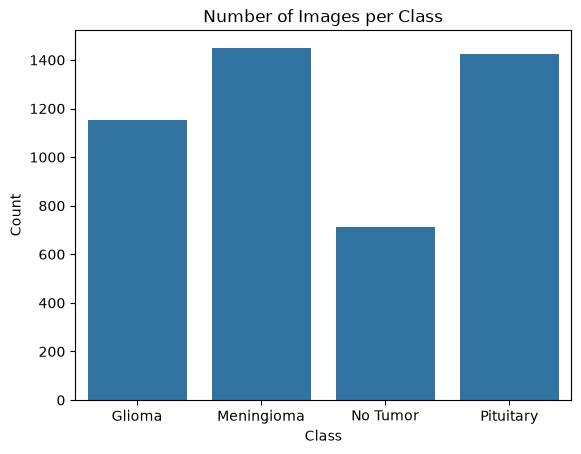

None

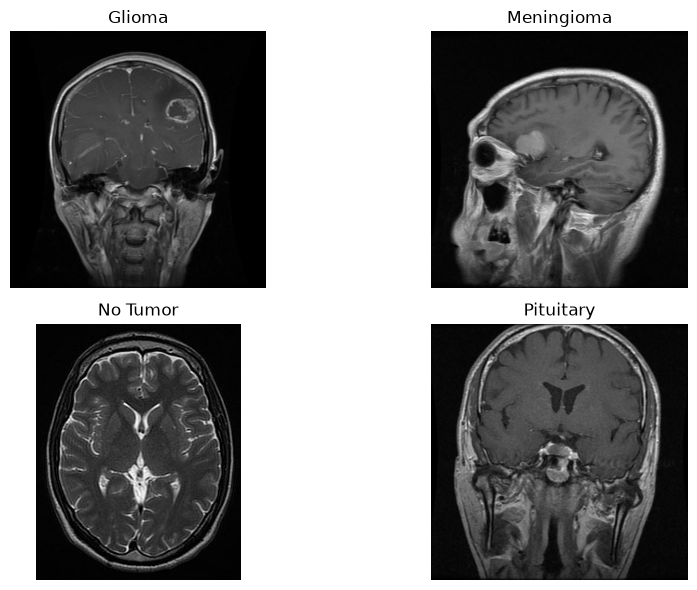

In [14]:

print("Training valid images:", len(train_valid))
print("Training invalid files:", len(train_invalid))

print("Validation valid images:", len(val_valid))
print("Validation invalid files:", len(val_invalid))


print("classes", os.listdir(TRAIN_DIR))

class_counts = {}

for class_name in class_names:
    count = 0
    for image_path in train_valid:
        if class_name in image_path:
            count += 1
    class_counts[class_name] = count
    
    df_counts = pd.DataFrame(list(class_counts.items()), columns=["Class", "Count"])
    
sns.barplot(x="Class", y="Count", data=df_counts)
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")
display(plt.show())

plt.figure(figsize=(10, 6))
for i,class_name in enumerate(class_names):
    image_path = random.choice([img_path for img_path in train_valid if class_name in img_path])
    image = Image.open(image_path)
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.axis('off')
    plt.title(class_name)
    
plt.tight_layout()
plt.show()

### Step 3

Répartir les images en trois ensembles : Train (70 %), Validation (15 %) et Test (15 %), puis compter et afficher le nombre d'images dans chaque ensemble.

In [15]:

X = train_valid + val_valid

def get_label_from_path(image_path):
    for class_name in class_names:
        if class_name in image_path:
            return class_name
    return None

def split_dataset(X):
    X_train, X_temp = train_test_split(
        X, test_size=0.3, random_state=42
    )

    X_val, X_test = train_test_split(
        X_temp, test_size=0.5, random_state=42
    )
    
    y_train = [get_label_from_path(path) for path in X_train]
    y_val = [get_label_from_path(path) for path in X_val]
    y_test = [get_label_from_path(path) for path in X_test]

    return X_train, X_val, X_test, y_train, y_val, y_test


X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(X)

print('train images:', len(X_train))
print('validation images:', len(X_val))
print('test images:', len(X_test))

train images: 3674
validation images: 787
test images: 788


### Step 4

Appliquer des techniques d'augmentation des données (blur, noise, flip) uniquement sur les données d'entraînement, afin d'enrichir les échantillons et de réduire les déséquilibres entre les classes.

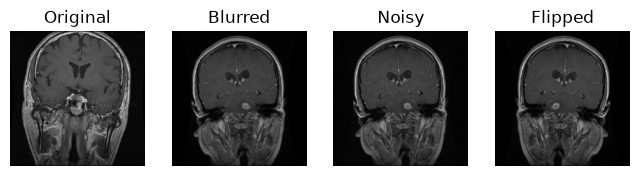

In [16]:
def augmentation(X_train):
    image_path = random.choice(X_train)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    blurred_image = cv2.GaussianBlur(image, (3, 3), 0)
    noise = np.random.randint(-15, 16, image.shape)
    noise_image = np.clip(image.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    flipped_image = cv2.flip(image, 1)
    plt.figure(figsize=(8, 4))
    return blurred_image,noise_image,flipped_image

blurred_image,noise_image,flipped_image = augmentation(X_train)

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(blurred_image)
plt.title("Blurred")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(noise_image)
plt.title("Noisy")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(flipped_image)
plt.title("Flipped")
plt.axis("off")

plt.show()

### Step 5

Charger avec image_dataset_from_directory() (redimensionnement, batch, shuffle=True pour le train), puis normaliser selon le modèle.

In [17]:
def create_dataset_and_normalize(directory, shuffle=True):
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory,
        image_size=(224, 224),
        batch_size=32,
        shuffle=shuffle
    )
    


    return dataset

train_dataset = create_dataset_and_normalize("./data/classification/Train", shuffle=True)
val_dataset = create_dataset_and_normalize("./data/classification/Val", shuffle=False)


Found 4737 files belonging to 4 classes.


I0000 00:00:1793110811.733778   86170 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA RTX 2000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 512 files belonging to 4 classes.


### Step 6

Charger le modèle préentraîné GoogLeNet (InceptionV3), geler ses couches de base, remplacer sa tête de classification par une nouvelle adaptée au nombre de classes, puis entraîner uniquement cette dernière (Feature Extraction).

In [18]:
def create_model():
    base_model = tf.keras.applications.InceptionV3(weights="imagenet",include_top=False, input_shape=(224,224,3))
    base_model.trainable = False
    inputs = tf.keras.Input(shape=(224,224,3))
    x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    outputs = tf.keras.layers.Dense(
        4,
        activation="softmax"
    )(x)
    model = tf.keras.Model(inputs, outputs)
    return model
model = create_model()

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,065,572 (84.17 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

### Step 7

Déterminer les hyperparamètres d'entraînement : learning rate, fonction de perte (loss) et optimiseur (optimizer).

In [ ]:
model = create_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=6, 
    restore_best_weights=True
)

checkpoint_callback = ModelCheckpoint(
    filepath="./brain_tumor_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)
callable = [early_stopping,checkpoint_callback]

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=25,
    callbacks=callable
)


Epoch 1/25


/root/tf-gpu/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-27 14:20:21.862456: I external/local_xla/xla/service/service.cc:163] XLA service 0x7dd4000556d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-27 14:20:21.862537: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-27 14:20:22.096887: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-27 14:20:23.921303: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92700
2026

  1/149 ━━━━━━━━━━━━━━━━━━━━ 45:59 19s/step - accuracy: 0.2812 - loss: 1.7116

I0000 00:00:1793110836.898007  110423 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.7661 - loss: 0.6063
Epoch 1: val_loss improved from None to 0.44512, saving model to ./brain_tumor_best.keras

Epoch 1: finished saving model to ./brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 41s 149ms/step - accuracy: 0.7661 - loss: 0.6063 - val_accuracy: 0.8320 - val_loss: 0.4451
Epoch 2/25
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8792 - loss: 0.3308
Epoch 2: val_loss improved from 0.44512 to 0.34795, saving model to ./brain_tumor_best.keras

Epoch 2: finished saving model to ./brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.8792 - loss: 0.3308 - val_accuracy: 0.8750 - val_loss: 0.3480
Epoch 3/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9162 - loss: 0.2340
Epoch 3: val_loss improved from 0.34795 to 0.29259, saving model to ./brain_tumor_best.keras

Epoch 3: finished saving model to ./brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.

### Step 8

Entraîner le modèle sur l'ensemble d'entraînement et suivre ses performances sur l'ensemble de validation.

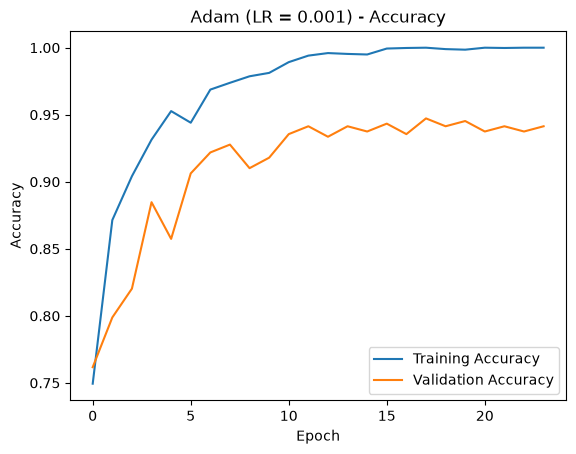

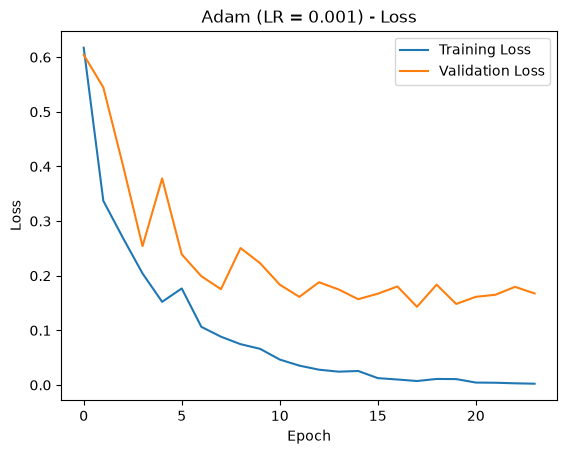

In [ ]:

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Adam (LR = 0.001) - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Adam (LR = 0.001) - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Step 9

Évaluer le modèle : accuracy, précision (precision), rappel (recall) et F1-score.

In [ ]:
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

y_pred_prob = model.predict(val_dataset)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=train_dataset.class_names
))


2026-10-26 16:32:17.104001: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step
Accuracy: 0.947265625

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.92      0.93      0.93       136
  Meningioma       0.92      0.94      0.93       140
    No Tumor       0.99      0.93      0.96       100
   Pituitary       0.98      0.99      0.98       136

    accuracy                           0.95       512
   macro avg       0.95      0.95      0.95       512
weighted avg       0.95      0.95      0.95       512



### Step 10

Analyser les résultats avec une matrice de confusion et comparer les performances sur les ensembles d'entraînement et de test.

2026-10-26 16:36:55.052227: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


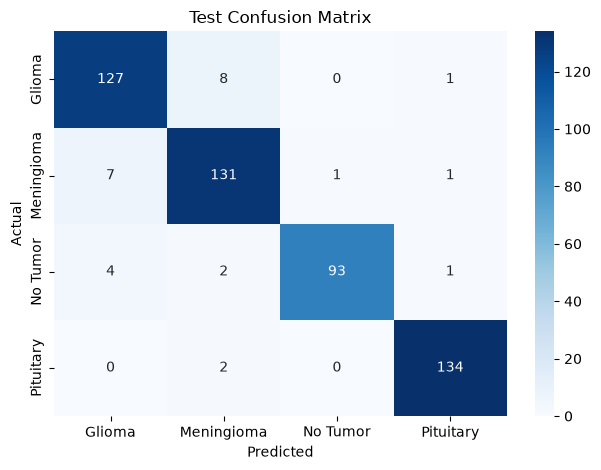

Train Accuracy: 0.2670466540004222
Test Accuracy: 0.947265625


In [ ]:
y_train_true = np.concatenate([labels.numpy() for images, labels in train_dataset])
y_test_true = np.concatenate([labels.numpy() for images, labels in val_dataset])
y_train_pred = np.argmax(model.predict(train_dataset), axis=1)
y_test_pred = np.argmax(model.predict(val_dataset), axis=1)

matrix = confusion_matrix(y_test_true, y_test_pred)

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("Train accuracy:", accuracy_score(y_train_true, y_train_pred))
print("Test accuracy:", accuracy_score(y_test_true, y_test_pred))

### Step 11

Dégeler les dernières couches du modèle préentraîné, poursuivre le fine-tuning avec un faible learning rate, réévaluer le modèle et comparer avec le modèle du Feature Extraction.

In [ ]:
base_model = model.layers[2]
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5
)

Epoch 1/5


/root/tf-gpu/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


### Step 12

Sauvegarder le modèle entraîné.

In [ ]:
model.save("./brain_tumor_finetuned.keras")
print("Model saved successfully.")

# PART 2 - Detection (YOLOv8)

### Step 1

Afficher un échantillon d'images avec leurs boîtes englobantes (bounding boxes) et les classes correspondantes.

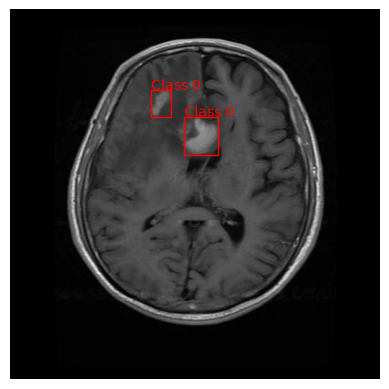

In [ ]:
def show_image_with_labels(image_path, label_path):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    plt.imshow(image)

    with open(label_path, "r") as file:
        for line in file:
            class_id, center_x, center_y, box_width, box_height = map(float, line.split())
            center_x = center_x * width
            center_y = center_y * height
            box_width = box_width * width
            box_height = box_height * height
            x = center_x - box_width / 2
            y = center_y - box_height / 2

            box = plt.Rectangle((x, y), box_width, box_height, fill=False, color="red")
            plt.gca().add_patch(box)
            plt.text(x, y, f"Class {int(class_id)}", color="red")

    plt.axis("off")
    plt.show()

image_path = "./data/classification/Train/Glioma/images/gg (3).jpg"
label_path = "./data/classification/Train/Glioma/labels/gg (3).txt"
show_image_with_labels(image_path, label_path)

### Step 2

Vérifier, pour chaque image, l'existence d'un fichier .txt correspondant dans le répertoire des annotations (comparer les noms de base des fichiers).

In [ ]:
def check_labels(split_folder, class_names):
    missing_labels = []
    extra_labels = []

    for class_name in class_names:
        image_folder = os.path.join(split_folder, class_name, "images")
        label_folder = os.path.join(split_folder, class_name, "labels")

        image_names = {
            os.path.splitext(file_name)[0]
            for file_name in os.listdir(image_folder)
        }
        label_names = {
            os.path.splitext(file_name)[0]
            for file_name in os.listdir(label_folder)
        }

        missing_labels.extend(image_names - label_names)
        extra_labels.extend(label_names - image_names)

    return missing_labels, extra_labels

train_missing, train_extra = check_labels(TRAIN_DIR, class_names)
val_missing, val_extra = check_labels(VAL_DIR, class_names)

print("Train missing labels:", len(train_missing))
print("Train extra labels:", len(train_extra))
print("Validation missing labels:", len(val_missing))
print("Validation extra labels:", len(val_extra))

NameError: name 'TRAIN_DIR' is not defined

### Step 3

Organiser les données dans les dossiers images et labels, en respectant les ensembles train, valid et test.

### Step 4

Copier chaque image avec son fichier d'annotation vers l'ensemble approprié.

### Step 5

Écarter les images sans annotation et les fichiers d'annotation sans image associée.

### Step 6

Vérifier la validité du format des annotations YOLO et la cohérence des classes.

### Step 7

Compter les images et les fichiers d'annotation dans chaque ensemble.

### Step 8

Créer un fichier data.yaml (chemins train/val/test, nombre de classes, noms des classes).

### Step 9

Définir les paramètres d'augmentation des données dans la configuration d'entraînement de YOLOv8.

### Step 10

Entraîner le modèle YOLOv8 avec des hyperparamètres adaptés au dataset et aux ressources disponibles.

### Step 11

Évaluer : précision, rappel, mAP@0.5 et mAP@0.5:0.95.

### Step 12

Analyser les résultats et vérifier la généralisation du modèle sur l'ensemble de test.

### Step 13

Sauvegarder le modèle entraîné et les artefacts nécessaires à son utilisation.

# PART 3 - MLflow

> Start the MLflow UI in another terminal with: mlflow ui

### Step 1

Configurer une expérience MLflow pour suivre les entraînements.

### Step 2

Enregistrer les hyperparamètres utilisés, les métriques obtenues et les artefacts pertinents.

### Step 3

Comparer plusieurs expériences afin d'identifier la configuration la plus performante.

### Step 4

Enregistrer le modèle retenu et conserver les informations nécessaires à son identification et sa réutilisation.

# Next
Airflow, FastAPI and Streamlit have their own files: airflow/dag_pipeline.py, api/main.py, app/streamlit_app.py